In [2]:
import pandas as pd

from src.dataprocessor import DataProcessor
from src.func_utils import (
    clean_features_by_type,
    generate_pairs_concat,
    save_pairs_to_excel,
    split_patients_no_leakage,
    variable_frequency_table,
    visualize_cleaning_results,
)

Xtrain_molecular: str = r"./data/molecular_train.csv"
Xtrain_clinical: str = r"./data/clinical_train.csv"
target_train: str = r"./data/target_train.csv"

data_train_mol: pd.DataFrame = pd.read_csv(Xtrain_molecular)
data_train_cli: pd.DataFrame = pd.read_csv(Xtrain_clinical)
target_df: pd.DataFrame = pd.read_csv(target_train)

# Convert 'OS_YEARS' to numeric, forcing errors to NaN
target_df['OS_YEARS'] = pd.to_numeric(target_df['OS_YEARS'], errors='coerce')

# Ensure 'OS_STATUS' is boolean
target_df['OS_STATUS'] = target_df['OS_STATUS'].astype(bool)

data = DataProcessor(data_train_mol, data_train_cli, target_df)

Let's quickly visualize our data to get familiar with it:

In [3]:
data.show()
data.get_data_shapes()

Molecular Data :
        ID CHR        START          END                REF ALT    GENE  \
0  P100000  11  119149248.0  119149248.0                  G   A     CBL   
1  P100000   5  131822301.0  131822301.0                  G   T    IRF1   
2  P100000   3   77694060.0   77694060.0                  G   C   ROBO2   
3  P100000   4  106164917.0  106164917.0                  G   T    TET2   
4  P100000   2   25468147.0   25468163.0  ACGAAGAGGGGGTGTTC   A  DNMT3A   

  PROTEIN_CHANGE                EFFECT     VAF   DEPTH  
0        p.C419Y  non_synonymous_codon  0.0830  1308.0  
1        p.Y164*           stop_gained  0.0220   532.0  
2            p.?   splice_site_variant  0.4100   876.0  
3       p.R1262L  non_synonymous_codon  0.4300   826.0  
4   p.E505fs*141    frameshift_variant  0.0898   942.0  

Clinical Data :
        ID CENTER  BM_BLAST    WBC  ANC  MONOCYTES    HB    PLT  \
0  P132697    MSK      14.0    2.8  0.2        0.7   7.6  119.0   
1  P132698    MSK       1.0    7.4  2.4

'the molecular data shape: (10935, 11), clinical data shape: (3323, 9), target data shape: (3323, 3)'

Let's start by briefly describing the database we have:

## Clinical Data (One Row per Patient)

Each patient is associated with a unique identifier and detailed clinical information:

* **ID:** Unique identifier for each patient.
* **CENTER:** The clinical center where the patient is treated.
* **BM_BLAST:** Percentage of blasts in the bone marrow, indicating the proportion of abnormal blood cells found in the patients' bone marrow.
* **WBC:** White Blood Cell count, measured in Giga/L (blood count parameter).
* **ANC:** Absolute Neutrophil Count in the blood, in Giga/L (blood count parameter).
* **MONOCYTES:** Number of monocytes in the blood, in Giga/L (blood count parameter).
* **HB:** Hemoglobin level, measured in g/dL (blood count parameter).
* **PLT:** Platelet count, in Giga/L (blood count parameter).
* **CYTOGENETICS:** Detailed description of the patient's karyotype, representing chromosomal abnormalities detected in blood cancer cells. Notations follow the ISCN standard, with typical markers like "46,XX" for a normal female karyotype or "46,XY" for a normal male karyotype. Abnormalities like monosomy 7 (loss of chromosome 7) indicate higher-risk disease.


## Molecular Gene Data (One Row per Somatic Mutation per Patient)

Somatic (acquired) mutations are mutations specific to cancer cells, not found in the patient's normal cells. This data captures genetic mutations at the cellular level:

* **ID:** Unique identifier for each patient.
* **CHR, START, END:** Chromosomal position of the mutation on the human genome.
* **REF, ALT:** The reference nucleotide and the alternative (mutant) nucleotide.
* **GENE:** The gene affected by the mutation.
* **PROTEIN_CHANGE:** The impact of the mutation on the protein produced by the gene.
* **EFFECT:** General classification of the mutation's impact on gene function.
* **VAF:** Variant Allele Fraction, representing the proportion of cells carrying the mutation.

## Target Data:
* **OS_STATUS**: Patient status (dead/alive) at last consultation
* **OS_YEARS**: How many years the patient has lived until now

We are interested in the frequency of our variables, as well as their missing values

In [4]:
freq_mol = variable_frequency_table(data.molecular_data)
freq_mol

,Variable,Unique_Values,Non_Missing_Count,Missing_Count,Non_Missing_%
0,ID,3026,10935,0,100.00%
1,CHR,23,10821,114,98.96%
2,START,4645,10821,114,98.96%
3,END,4664,10821,114,98.96%
4,REF,406,10821,114,98.96%
5,ALT,332,10821,114,98.96%
6,GENE,124,10935,0,100.00%
7,PROTEIN_CHANGE,4686,10923,12,99.89%
8,EFFECT,16,10935,0,100.00%
9,VAF,2952,10846,89,99.19%


We see that the variables START / END / REF / ALT / PROTEIN_CHANGE have very high variability relative to the number of observations we have, so we will not keep them.

In [5]:
mol_col_to_remove = ["START","END","REF","ALT","PROTEIN_CHANGE"]
data.remove_columns(mol_col_to_remove, data_type="molecular")

We will do the same for clinical data

In [6]:
freq_clin = variable_frequency_table(data.clinical_data)
freq_clin

,Variable,Unique_Values,Non_Missing_Count,Missing_Count,Non_Missing_%
0,ID,3323,3323,0,100.00%
1,CENTER,23,3323,0,100.00%
2,BM_BLAST,139,3214,109,96.72%
3,WBC,699,3051,272,91.81%
4,ANC,1026,3130,193,94.19%
5,MONOCYTES,609,2722,601,81.91%
6,HB,239,3213,110,96.69%
7,PLT,586,3199,124,96.27%
8,CYTOGENETICS,1194,2936,387,88.35%


In the clinical table, the only problematic variable is CYTOGENETICS. It carries too much information to discard, so we map each karyotype to a risk category (normal / intermediate / adverse) inspired by the ELN 2022 classification. The rules are in `DataProcessor.classify_cytogenetics` (`src/dataprocessor.py`).

In [7]:
data.apply_cytogenetics_classification()
data.create_cytogenetics_dummies()

,ID,CENTER,BM_BLAST,WBC,ANC,MONOCYTES,HB,PLT,CYTO_adverse,CYTO_intermediate,CYTO_normal
0,P132697,MSK,14.0,2.80,0.20,0.70,7.6,119.0,False,True,False
1,P132698,MSK,1.0,7.40,2.40,0.10,11.6,42.0,False,False,True
2,P116889,MSK,15.0,3.70,2.10,0.10,14.2,81.0,True,False,False
3,P132699,MSK,1.0,3.90,1.90,0.10,8.9,77.0,False,True,False
4,P132700,MSK,6.0,128.00,9.70,0.90,11.1,195.0,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...
3318,P121828,VU,1.0,3.70,2.53,0.53,8.9,499.0,False,False,True
3319,P121829,VU,0.0,4.20,2.40,0.22,10.6,49.0,False,True,False
3320,P121830,VU,0.0,1.80,0.55,0.29,9.4,86.0,True,False,False
3321,P121853,VU,5.0,1.37,0.37,0.11,11.4,102.0,False,True,False


## Molecular data

We create a DANGER variable, the product of VAF and DEPTH, as a proxy for how strongly a mutation is expressed (a mutation is assumed more dangerous when its variant allele frequency and read depth are higher).
We then aggregate per patient, using binary encoding for genes, chromosomes and effects.

In [8]:
data.add_danger()
data.aggregate_genes()
data.temporary.head()

,ID,DANGER,GENE_ABL1,GENE_ARID1A,GENE_ARID2,GENE_ASXL1,GENE_ASXL2,GENE_ATRX,GENE_BAP1,GENE_BCL10,...,WBC,ANC,MONOCYTES,HB,PLT,CYTO_adverse,CYTO_intermediate,CYTO_normal,OS_YEARS,OS_STATUS
0,P100000,1323.4786,False,False,False,False,False,False,False,False,...,7.50,4.65,NaN,8.8,406.0,True,False,False,5.819178,False
1,P100001,271.2100,False,False,False,False,False,False,False,False,...,7.21,2.88,NaN,9.8,364.0,True,False,False,2.857534,False
2,P100002,351.8090,False,False,False,False,False,False,False,False,...,2.60,0.49,NaN,8.9,35.0,True,False,False,0.306849,True
3,P100004,607.9536,False,False,False,False,False,False,False,False,...,2.55,1.56,NaN,7.0,708.0,False,False,True,5.186301,False
4,P100006,490.1980,False,False,False,False,False,False,False,False,...,1.23,0.48,NaN,7.6,105.0,False,True,False,4.917808,False


In [9]:
selection = clean_features_by_type(data.temporary, target_col="OS_YEARS")

VARIABLE CLASSIFICATION
Numeric variables (7):
  DANGER, BM_BLAST, WBC, ANC, MONOCYTES, HB, PLT

Categorical variables (169):
  ID, GENE_ABL1, GENE_ARID1A, GENE_ARID2, GENE_ASXL1, GENE_ASXL2, GENE_ATRX, GENE_BAP1, GENE_BCL10, GENE_BCOR...

COMPUTING ASSOCIATIONS WITH THE TARGET

CLEANING NUMERIC VARIABLES
Initial: 7 variables
Kept: 4 variables
Removed: 3 variables

Selected numeric variables (by correlation):
  - PLT: |r| = 0.177
  - HB: |r| = 0.174
  - BM_BLAST: |r| = 0.156
  - DANGER: |r| = 0.130

CLEANING CATEGORICAL VARIABLES
Initial: 169 variables
Kept: 39 variables
Removed: 130 variables

Selected categorical variables (by Chi² p-value):
  - OS_STATUS: p = 0.0000
  - GENE_TP53: p = 0.0000
  - CENTER: p = 0.0000
  - CHR_17: p = 0.0000
  - CYTO_adverse: p = 0.0000
  - CHR_21: p = 0.0000
  - GENE_RUNX1: p = 0.0000
  - GENE_SF3B1: p = 0.0000
  - CYTO_normal: p = 0.0000
  - GENE_ASXL1: p = 0.0000
  - CHR_1: p = 0.0000
  - GENE_STAG2: p = 0.0000
  - GENE_EZH2: p = 0.0000
  - CHR_2: p =

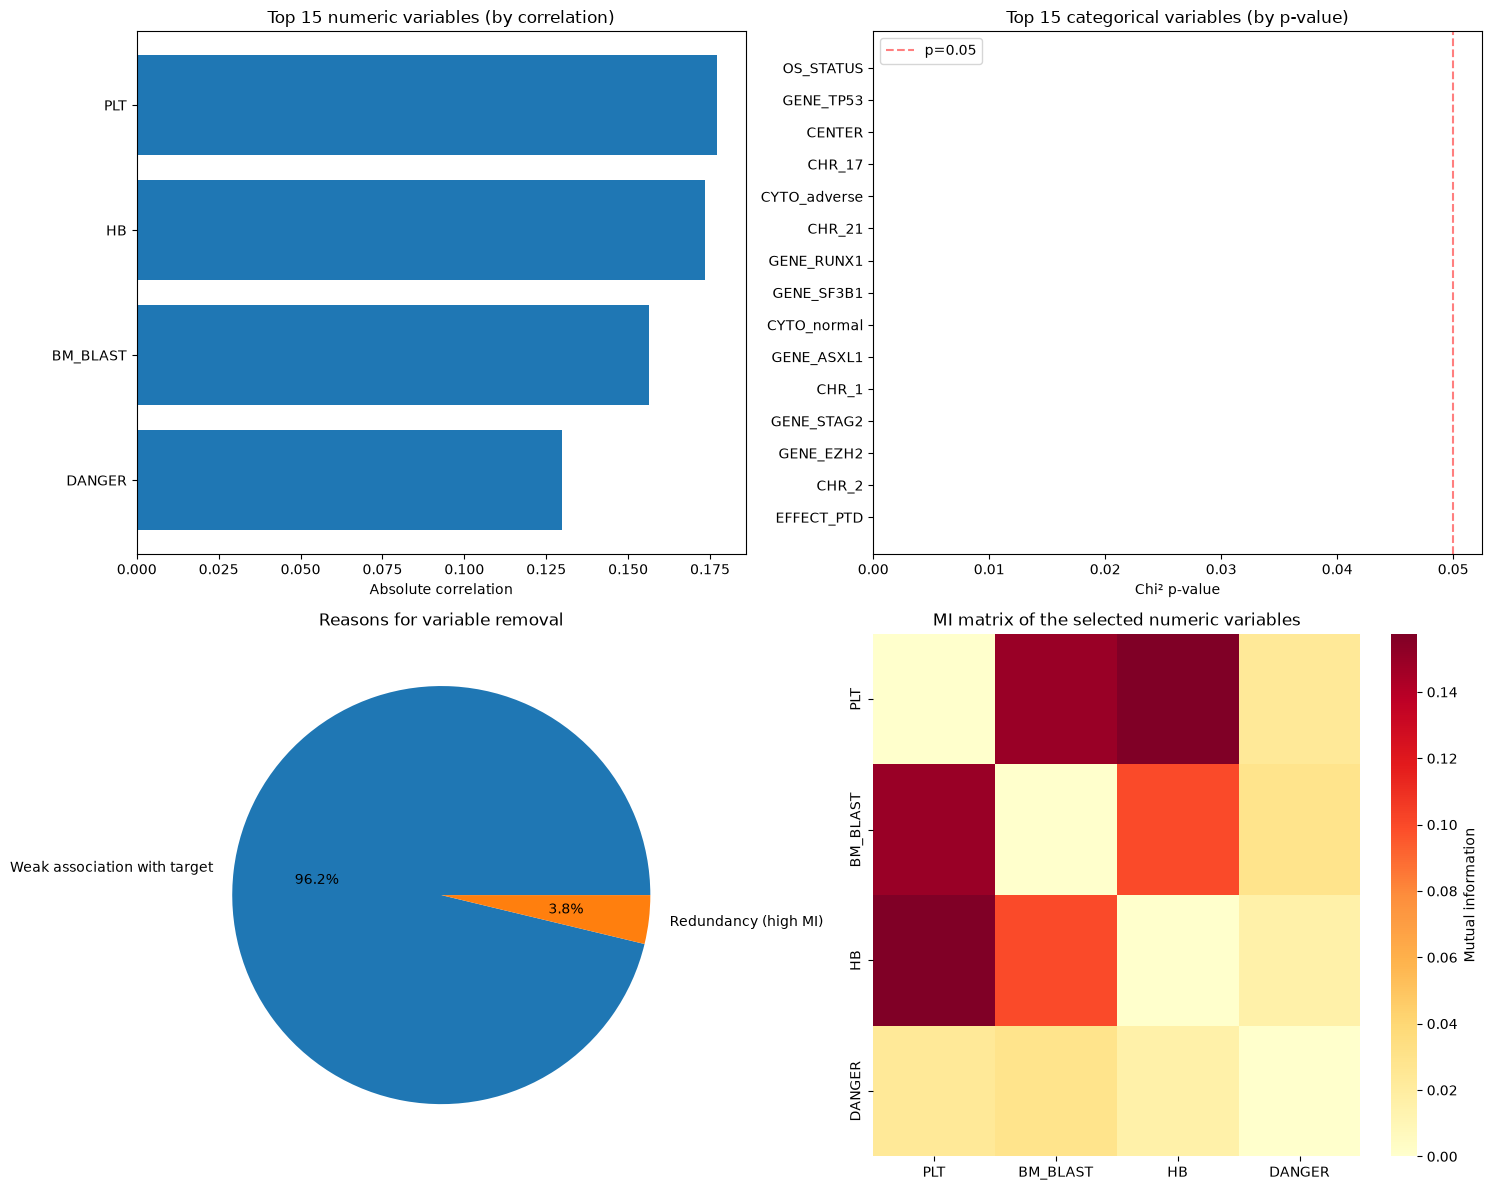

In [10]:
visualize_cleaning_results(selection)

The p-values are not displayed because they are too small.

We obtain our final list and rearrange it to make it cleaner

In [11]:
cols_for_training = selection[1] + selection[2]
if "OS_STATUS" in cols_for_training:
    cols_for_training.remove("OS_STATUS")
cols_for_training.remove("CENTER")
cols_for_training = ["ID"] + cols_for_training + ["OS_STATUS", "OS_YEARS"]

In [12]:
data.temporary[cols_for_training].isna().sum()

ID                                 0
PLT                              114
BM_BLAST                         100
HB                               100
DANGER                             0
CYTO_normal                        0
GENE_RUNX1                         0
GENE_PTPN11                        0
GENE_NRAS                          0
EFFECT_frameshift_variant          0
GENE_BCOR                          0
GENE_ASXL1                         0
CHR_1                              0
CYTO_adverse                       0
GENE_CUX1                          0
GENE_NPM1                          0
CHR_2                              0
GENE_RAD21                         0
GENE_U2AF2                         0
GENE_GATA2                         0
CHR_13                             0
GENE_FLT3                          0
GENE_U2AF1                         0
GENE_CDKN2A                        0
CHR_17                             0
GENE_TP53                          0
CHR_19                             0
C

We will handle the missing data later

In [13]:
data.save_data(cols = cols_for_training)

,ID,PLT,BM_BLAST,HB,DANGER,CYTO_normal,GENE_RUNX1,GENE_PTPN11,GENE_NRAS,EFFECT_frameshift_variant,...,GENE_SF3B1,CHR_X,CHR_11,GENE_MLL,GENE_SRSF2,EFFECT_PTD,GENE_JAK2,GENE_EZH2,OS_STATUS,OS_YEARS
0,P100000,406.0,3.0,8.8,1323.4786,False,False,False,False,True,...,False,False,True,False,False,False,False,False,False,5.819178
1,P100001,364.0,2.0,9.8,271.2100,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,2.857534
2,P100002,35.0,15.0,8.9,351.8090,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,0.306849
3,P100004,708.0,3.0,7.0,607.9536,True,False,False,False,True,...,False,True,False,False,False,False,False,False,False,5.186301
4,P100006,105.0,1.0,7.6,490.1980,False,False,False,False,True,...,False,False,False,False,True,False,True,False,False,4.917808
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3021,P132725,61.0,12.0,11.5,4365.4240,True,False,False,False,True,...,False,True,False,False,False,False,False,False,False,4.290411
3022,P132726,383.0,15.0,11.2,347.0100,True,False,False,False,False,...,False,False,True,True,False,False,False,False,False,2.279452
3023,P132727,44.0,5.0,11.3,816.5240,True,False,False,False,True,...,False,False,True,False,False,False,False,False,False,0.578082
3024,P132728,14.0,2.0,8.2,2989.9348,False,False,False,True,False,...,False,False,False,False,False,False,False,False,True,1.284932


In [14]:
X, Y = data.treated_data.drop(columns=["OS_STATUS", "OS_YEARS"]), data.treated_data[["OS_STATUS", "OS_YEARS"]]

In [15]:
# Step 1: split PATIENTS first, so no patient appears in two sets
X_train, Y_train, X_val, Y_val, X_test, Y_test = split_patients_no_leakage(
    X, Y,
    train_size=0.6,
    val_size=0.2,
    test_size=0.2,
    random_state=42,
    id_column='ID'
)

# Step 2: build pairs separately inside each set
X_pairs_train, y_pairs_train, ids_train = generate_pairs_concat(
    X_train, Y_train,
    max_pairs=800000,
    include_abs_diff=False,
    id_column='ID'
)

X_pairs_cal, y_pairs_cal, ids_cal = generate_pairs_concat(
    X_val, Y_val, max_pairs=100000,
    include_abs_diff=False,
    id_column='ID'
)

X_pairs_test, y_pairs_test, ids_test = generate_pairs_concat(
    X_test, Y_test, max_pairs=100000,
    include_abs_diff=False,
    id_column='ID'
)

print("\nSummary:")
print(f"Train:       {len(y_pairs_train)} pairs")
print(f"Calibration: {len(y_pairs_cal)} pairs")
print(f"Test:        {len(y_pairs_test)} pairs")

Split done with no patient leakage:
  Train: 1815 patients (60.0%)
  Val:   605 patients (20.0%)
  Test:  606 patients (20.0%)
  ✓ No patient overlap detected
CONCAT: 445575 pairs generated, 82 features per pair
CONCAT: 56725 pairs generated, 82 features per pair
CONCAT: 56938 pairs generated, 82 features per pair

Summary:
Train:       445575 pairs
Calibration: 56725 pairs
Test:        56938 pairs


# Data processing

Load the clinical, molecular and survival data, engineer features, select variables, split patients into train / calibration / test sets and build the patient pairs used by every model.

In [17]:
save_pairs_to_excel(
    X_pairs_train, y_pairs_train, ids_train,
    X_pairs_cal, y_pairs_cal, ids_cal,
    X_pairs_test, y_pairs_test, ids_test)


✓ Data saved to 'data/processed_data.xlsx'
  - Sheet 'train': 445575 pairs
  - Sheet 'calibration': 56725 pairs
  - Sheet 'test': 56938 pairs


{'train':                patient_ids feat_0 feat_1 feat_2     feat_3 feat_4 feat_5  \
 0       (P105712, P122349)  166.0    9.0   11.8  2532.0401  False  False   
 1       (P120377, P121051)   17.0    NaN   11.3   1062.232  False  False   
 2       (P116631, P122456)  150.0    4.0   10.9    1115.62   True  False   
 3       (P103003, P102571)   14.0    3.0    6.4    852.705  False  False   
 4       (P116623, P118399)   18.0   11.0   11.0  1983.6317  False   True   
 ...                    ...    ...    ...    ...        ...    ...    ...   
 445570  (P110842, P118789)  174.0    1.0   10.8  1048.1656  False   True   
 445571  (P110894, P131861)  132.0    2.0   10.8  1019.0584   True  False   
 445572  (P118490, P122399)  106.0   10.0   12.6    274.765  False  False   
 445573  (P100127, P118487)   84.0   18.0   10.0    392.808   True  False   
 445574  (P118481, P121088)   24.0    4.0   10.5   1826.341   True  False   
 
        feat_6 feat_7 feat_8  ... feat_73 feat_74 feat_75 feat_76